URL Dashboard Table: https://public.tableau.com/app/profile/ryan.pratama7647/viz/P1M2_ryan_farid/Dashboard1?publish=yes

# A. Milestone 2

Nama    : Ryan Farid Pratama <br>
Batch   : CODA-RMT-023

Milestone 2 ini dibuat untuk melakukan evaluasi dan identifikasi tingkat kesenjangan sebaran, rasio cakupan per 100.000 penduduk, dan rasio berbasis PDRB pada stasiun SPKLU di tingkat kabupaten/provinsi seluruh Indonesia untuk mendeteksi wilayah yang mengalami krisis pengisian daya (_charging deserts_)


# B. Identifikasi Masalah
Tahapan ini berisi topik permasalahan, problem statement, latar belakang, hinga penjabaran masalah atau _key questions_ yang akan dianalisis menggunakan metode statistik dan data visualisasi.

## B.1 Latar Belakang

Indonesia telah memutuskan komitmen nasional untuk mempercepat transisi Kendaraan Bermotor Listrik Berbasis Baterai (KBLBB) melalui Peraturan Presiden No. 55 Tahun 2019, dengan target 15 juta unit EV yang beroperasi pada tahun 2030 serta penghentian bertahap penjualan kendaraan konvensional (ICE) pada tahun 2050.

Keberhasilan pencapaian target nasional ini sangat bergantung pada ketersediaan dan kemampuan jangkauan infrastruktur Stasiun Pengisian Kendaraan Listrik Umum (SPKLU). Namun, pesatnya pertumbuhan kendaraan listrik di wilayah perkotaan memicu kekhawatiran timbulnya kesenjangan aksesibilitas spasial dan pembentukan "gurun pengisian daya" (_charging deserts_) di luar pusat pertumbuhan ekonomi utama. Tanpa pemetaan spasial yang objektif mengenai sebaran stasiun, rasio cakupan penduduk, serta porsi peran antara BUMN (PT PLN) dan pihak swasta, pembangunan infrastruktur berisiko tidak efisien dan menghambat adopsi EV secara nasional. Oleh karena itu, diperlukan evaluasi berbasis data spasial nasional untuk mengidentifikasi tingkat ketimpangan sebaran SPKLU di seluruh provinsi Indonesia per 100.000 penduduk berdasarkan kapita/PDRB.

## B.2 Tujuan

Melakukan evaluasi dan identifikasi tingkat kesenjangan sebaran, rasio cakupan per 100.000 penduduk, dan rasio berbasis PDRB pada stasiun SPKLU di tingkat kabupaten/provinsi seluruh Indonesia untuk mendeteksi wilayah krisis pengisian daya (_charging deserts_)

## B.3 Problem Statements

Melakukan evaluasi dan identifikasi tingkat ketimpangan sebaran, rasio cakupan per 100.000 penduduk, dan rasio per triliun Rupiah PDRB pada jaringan SPKLU tingkat kabupaten/provinsi di Indonesia untuk mendeteksi wilayah krisis pengisian daya (_charging desserts_) untuk PT PLN (Persero) berdasarkan data nasional tahun 2025/2026.

### B.3.1. SMART Method
1. Specific (S): Evaluasi sebaran, rasio per kapita/PDRB, dan pemetaan _charging deserts_ pada jaringan SPKLU Indonesia.
2. Measurable (M): Mengukur rasio stasiun per 100.000 penduduk (`stations_per_100k`), rasio per triliun PDRB (`stations_per_trillion_gdp`), dan proporsi stasiun terisolasi (`nearest_road_km` > 20 km).
3. Achievable (A): Dihitung langsung dari penggabungan tabel stasiun (`spklu_stations`) dan tabel BPS provinsi (`spklu_provinces`).
4. Relevant (R): Memberikan pemetaan obyektif bagi PT PLN dan Kementerian Perhubungan dalam mendeteksi area krisis pengisian daya.
5. Time-bound (T): Berdasarkan dataset spasial SPKLU nasional 2025/2026

### B.3.2. Key Questions
1. Bagaimana proporsi dan distribusi stasiun SPKLU yang dikuasai oleh PT PLN (Persero) dibandingkan CPO swasta independen dan dealer otomotif?
2. Bagaimana sebaran tingkat daya pengisian pada masing-masing kategori lokasi?
3. Provinsi mana saja yang memiliki rasio cakupan SPKLU terendah per 100.000 penduduk (`stations_per_100k`) dan per triliun Rupiah PDRB (`stations_per_trillion_gdp`)?
4. Berapa proporsi stasiun SPKLU yang tergolong charging desserts (terisolasi secara spasial dengan `nearest_road_km`>20 km dari stasiun lain)?
5. Berapa nilai rata-rata (mean), nilai tengah (median), standar deviasi, jangkauan antar-kuartil (IQR), serta batas pencilan (outliers) dari kapasitas daya dan jarak antar-stasiun di seluruh 2.454 lokasi?
6. Apakah terdapat perbedaan yang signifikan secara statistik antara rata-rata kapasitas daya terpasang atau jarak antar-stasiun di wilayah Jawa vs. Luar Jawa?

# C. Data Loading

Bagian ini berisi proses data loading dataset sumber data mulai dari library imports hingga melakukan eksplorasi data sederhana.

## C.1 Library Imports

In [1]:
# Manipulasi data & DataFrame
import pandas as pd
import numpy as np

# Statistik, Uji Hipotesis, dan Korelasi (WAJIB ADA)
import scipy.stats as stats

# Visualisasi data
import matplotlib.pyplot as plt

# Visualisasi scatterplot
!pip install seaborn
import seaborn as sns

# Mengabaikan warning agar output bersih
import warnings
warnings.filterwarnings("ignore")


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## C.2 Data Loading
Melakukan impor dataset yang berasal Mendeley <br>
URL: https://data.mendeley.com/datasets/z2bvd5r574/2 <br>
Kontributor : Richard Wiputra, Sherly Santiadi <br>
Institusi : BINUS University <br>

Dataset yang tersedia terdiri dari 5 tabel terpisah yaitu:
1. **spklu_stations** <br>
Tabel utama yang berisi informasi setiap titik lokasi SPKLU meliputi nama, tempat, merek operator hingga wilayah administratif
2. **spklu_chargers** <br>
Tabel yang berisi rincian teknis mengenai spesifikasi stasiun pengisi daya, besaran kapasitas daya hingga kategori power tier
3. **spklu_province_coverage** <br>
Tabel yang berisi cakupan layanan SPKLU di tingkat provinsi serta menyediakan data demografi dan ekonomi (Rasio Per Kapita dan PDRB per Provinsi)
4. **spklu_province_indicators** <br>
Tabel yang berisi data statistik demografi tingkat provinsi
5. **spklu_regency_codes** <br>
Tabel referensi yang memuat daftar nama/kode tingkat kabupaten/kota


Untuk menjawab ke 6 Key Questions, hanya dibutuhkan 2 tabel yaitu spklu_stations dan spklu_province_coverage yang kemudian digabungkan menjadi satu DataFrame.

In [ ]:
# Melakukan impor dan membaca isi dokumen CSV dataset
stations = pd.read_csv(r"portfolio\indonesia-spklu-coverage-analysis\A Geospatial Dataset of Public Electric Vehicle\data\spklu_stations.csv")

# Melakukan impor dan membaca isi dokumen CSV dataset
coverages = pd.read_csv(r"portfolio\indonesia-spklu-coverage-analysis\A Geospatial Dataset of Public Electric Vehicle\reference\spklu_province_coverage.csv")

## C.3 Data Exploration
Melakukan eksplorasi data sederhana DataFrame seperti melihat struktur data, tipe data kolom hingga penggunaan memori

### C.3.1 Tabel Stations
Melakukan eksplorasi data sederhana terhadap tabel spklu_stations / stations

In [3]:
# Menampilkan informasi ringkas terkait struktur DataFrame, seperti tipe data kolom, jumlah nilai non-null, dan penggunaan memori 
stations.info()

<class 'pandas.DataFrame'>
RangeIndex: 2454 entries, 0 to 2453
Data columns (total 44 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   station_id                 2454 non-null   int64  
 1   location_name              2454 non-null   str    
 2   address                    2451 non-null   str    
 3   provider_type              2454 non-null   str    
 4   operator_brand             821 non-null    str    
 5   location_type              2454 non-null   str    
 6   location_group             2454 non-null   str    
 7   province_name              2454 non-null   str    
 8   bps_province_code          2454 non-null   int64  
 9   regency_city_raw           2454 non-null   str    
 10  regency_city_clean         2454 non-null   str    
 11  admin_level                2454 non-null   str    
 12  bps_regency_code           2454 non-null   int64  
 13  latitude                   2454 non-null   float64
 14  lon

**Penjelasan:** <br>
Eksplorasi ini menunjukkan:
1. Total baris di dalam tabel sejumlah 2454 baris dan jumlah kolom sebanyak 44 kolom 
2. Terdapat 3 jenis tipe data yaitu int64 (angka tanpa nominal) sebanyak 14 kolom, str (karakter huruf) sebanyak 22 kolom dan float64 (angka dengan nominal) sebanyak 8 kolom. 
3. Dari 44 kolom, terdapat 7 kolom yang memiliki data kosong seperti kolom 'operator_brand'
4. Jumlah memori yang digunakan adalah 4.9 mb

In [4]:
# Menampilkan 10 baris data teratas
stations.head(10)

,station_id,location_name,address,provider_type,operator_brand,location_type,location_group,province_name,bps_province_code,regency_city_raw,...,stations_within_1km_ids,stations_within_3km,stations_within_3km_names,stations_within_3km_ids,stations_within_5km,stations_within_5km_names,stations_within_5km_ids,local_density_1km,local_density_3km,local_density_5km
0,4,SPKLU Tangcity,"Jl. Jenderal Sudirman No.1, Cikokol",PLN / SPKLU network,NaN,Mall / Shopping,Retail & Commercial,Banten,36,Kota Tangerang,...,2408|1663|1885,15,AUTO2000 Tangerang|SPKLU Eco Business Park|Ast...,2408|811|2143|2286|1663|638|1885|2493|382|2658...,29,AUTO2000 Tangerang|SPKLU Eco Business Park|Ast...,2408|811|2143|2286|1663|414|638|3|1885|2493|22...,0.95,0.53,0.37
1,6,SPKLU PLN ULP Medan Kota,Jl. Listrik No. 8 Medan,PLN / SPKLU network,NaN,PLN / Utility facility,Utility (PLN site),Sumatera Utara,12,Kota Medan,...,680|2596|795|2165|2963,17,SPKLU CityView Medan|Hyundai SM Raja (Khusus K...,59|2098|2407|680|405|2596|2387|992|981|977|229...,26,SPKLU CityView Medan|(WULING) Arista SM Raja|H...,59|2256|2098|1926|2407|680|405|2596|2387|991|5...,1.59,0.60,0.33
2,9,SPKLU PLN ULP DENPASAR,JL. P.B. Sudirman,PLN / SPKLU network,NaN,PLN / Utility facility,Utility (PLN site),Bali,51,Kota Denpasar,...,1968|1425|303,10,SPKLU DITLANTAS POLDA BALI|SPKLU BANK BTN KC D...,290|1968|63|669|1425|303|2827|1639|1035|353,21,SPKLU DITLANTAS POLDA BALI|(VOLTRON) McDonald'...,290|2917|1968|63|3040|669|2324|1415|2749|731|1...,0.95,0.35,0.27
3,10,SPKLU REST AREA (TRAVOY) KM 519 A Ruas Solo-Ngawi,"Dusun III, Karang Malang, Masaran",Independent CPO,Travoy,Rest area / Toll,Transport corridor,Jawa Tengah,33,Kab Sragen,...,NaN,0,NaN,NaN,0,NaN,NaN,0.00,0.00,0.00
4,13,SPKLU PLN ULP Embong Wungu,"Jl. Dr. Soetomo No. 42,Tegalsari",PLN / SPKLU network,NaN,PLN / Utility facility,Utility (PLN site),Jawa Timur,35,Kota Surabaya,...,2064,11,SPKLU Center Surabaya|(DayaGreen) Hotel Pop Di...,1838|2809|2997|933|2064|2650|60|2458|1362|2605...,22,SPKLU PT PJB|SPKLU HOTEL NARITA SURABAYA|SPKLU...,74|860|2942|2295|2989|1838|2809|2997|2955|2405...,0.32,0.39,0.28
5,17,SPKLU PLN ULP Mattoanging,"Jl. DR. Ratulangi, Mangkura",PLN / SPKLU network,NaN,PLN / Utility facility,Utility (PLN site),Sulawesi Selatan,73,Kota Makassar,...,NaN,12,(VOLTRON) BYD Haka Auto Karebosi|(WULING) Kuma...,2905|2337|2991|2992|2077|1225|2317|2969|407|21...,19,(VOLTRON) BYD Haka Auto Karebosi|(WULING) Kuma...,2905|2320|2337|39|2991|2992|2413|2418|2077|122...,0.00,0.42,0.24
6,20,SPKLU PLN UP3 Situbondo,"Jl. Cempaka No. 35, Situbondo",PLN / SPKLU network,NaN,PLN / Utility facility,Utility (PLN site),Jawa Timur,35,Kab Situbondo,...,NaN,0,NaN,NaN,0,NaN,NaN,0.00,0.00,0.00
7,21,Pelabuhan Ketapang Banyuwangi,"Jl. Raya Banyuwangi Situbondo, Lkr. Kp. Baru, ...",Other / unknown,NaN,Airport / Port / Transit,Transport corridor,Jawa Timur,35,Kab Banyuwangi,...,NaN,0,NaN,NaN,0,NaN,NaN,0.00,0.00,0.00
8,28,SPKLU Els Coffee Roastery Lampung,"Kalibalau Kencana, Sukabumi Sub-District, Band...",PLN / SPKLU network,NaN,Retail / F&B,Retail & Commercial,Lampung,18,Kota Bandar Lampung,...,1650,2,SPKLU Mall Transmart Carrefour Bandar Lampung|...,1095|1650,9,SPKLU PLN UP3 TANJUNG KARANG|SPKLU IBI DARMAJA...,401|1201|2406|1132|1166|1095|1651|1650|1202,0.32,0.07,0.11
9,31,"SPKLU PLN Kampung Ujung, Labuan Bajo","Lokasi Parkir Kampung Ujung Labuan Bajo, Kabup...",PLN / SPKLU network,NaN,Other / Unclassified,Other / Unclassified,Nusa Tenggara Timur,53,Kab Manggarai Barat,...,NaN,3,Parkir Polres Manggarai Barat|SPKLU PLN ULP LA...,351|1394|1393,3,Parkir Polres Manggarai Barat|SPKLU PLN ULP LA...,351|1394|1393,0.00,0.11,0.04


**Penjelasan:** <br>
Eksplorasi ini menunjukkan:
1. 10 baris pertama yang riil dari seluruh tabel
2. Indeks dimulai dari angka 0

In [5]:
# Menampilkan data kolom yang kosong
stations.isnull().sum()

station_id                      0
location_name                   0
address                         3
provider_type                   0
operator_brand               1633
location_type                   0
location_group                  0
province_name                   0
bps_province_code               0
regency_city_raw                0
regency_city_clean              0
admin_level                     0
bps_regency_code                0
latitude                        0
longitude                       0
station_power_kW                0
station_power_tier              0
type_charge_source              0
n_chargerboxes                  0
total_chargers                  0
total_connectors                0
max_box_power_kW                0
box_types                       0
status_active                   0
colocation_cluster_id           0
colocation_cluster_size         0
quality_flags                   0
merged_from_station_ids         0
n_merged                        0
nearest_road_k

**Penjelasan:** <br>
Eksplorasi ini menunjukkan:
1. Kolom 'address' memiliki 3 baris kosong
2. Kolom 'operator_brand' memiliki 1633 baris kosong
3. Kolom 'stations_within_1km_names' memiliki 1357 baris kosong
4. Kolom 'stations_within_1km_ids' memiliki 1357 baris kosong
5. Kolom 'stations_within_3km_names' memiliki 716 baris kosong
6. Kolom 'stations_within_3km_ids' memiliki 716 baris kosong
7. Kolom 'stations_within_5km_names' memiliki 560 baris kosong
8. Kolom 'stations_within_5km_ids' memiliki 560 baris kosong

In [6]:
# Menghitung total baris duplikat
total_duplikat = stations.duplicated().sum()
print(f"Jumlah baris duplikat: {total_duplikat}")

Jumlah baris duplikat: 0


### C.3.2 Tabel Coverages
Melakukan eksplorasi data sederhana terhadap tabel spklu_province_coverage / coverages

In [7]:
# Menampilkan informasi ringkas terkait struktur DataFrame, seperti tipe data kolom, jumlah nilai non-null, dan penggunaan memori 
coverages.info()

<class 'pandas.DataFrame'>
RangeIndex: 34 entries, 0 to 33
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   bps_province_code          34 non-null     int64  
 1   province_name              34 non-null     str    
 2   population_sp2020          34 non-null     int64  
 3   grdp_current_idr_billion   34 non-null     int64  
 4   grdp_year                  34 non-null     int64  
 5   bev_registered             0 non-null      float64
 6   n_stations                 34 non-null     int64  
 7   n_chargers                 34 non-null     int64  
 8   n_connectors               34 non-null     int64  
 9   total_installed_kW         34 non-null     float64
 10  stations_per_100k          34 non-null     float64
 11  chargers_per_100k          34 non-null     float64
 12  kW_per_10k                 34 non-null     float64
 13  stations_per_trillion_gdp  34 non-null     float64
 14  charger

**Penjelasan:** <br>
Eksplorasi ini menunjukkan:
1. Total baris di dalam tabel sejumlah 34 baris dan jumlah kolom sebanyak 14 kolom 
2. Terdapat 3 jenis tipe data yaitu int64 (angka tanpa nominal) sebanyak 7 kolom, str (karakter huruf) sebanyak 1 kolom dan float64 (angka dengan nominal) sebanyak 7 kolom. 
3. Dari 14 kolom, terdapat 2 kolom yang memiliki data kosong seperti kolom 'bev_registered'
4. Jumlah memori yang digunakan adalah 4.5 kb

In [8]:
# Menampilkan 10 baris data teratas
coverages.head(10)

,bps_province_code,province_name,population_sp2020,grdp_current_idr_billion,grdp_year,bev_registered,n_stations,n_chargers,n_connectors,total_installed_kW,stations_per_100k,chargers_per_100k,kW_per_10k,stations_per_trillion_gdp,chargers_per_1000_bev
0,11,Aceh,5274871,257502,2025,NaN,30,39,41,1016.0,0.569,0.739,1.926,0.117,NaN
1,12,Sumatera Utara,14799361,1236194,2025,NaN,90,174,149,3571.0,0.608,1.176,2.413,0.073,NaN
2,13,Sumatera Barat,5534472,352189,2025,NaN,64,115,94,1446.0,1.156,2.078,2.613,0.182,NaN
3,14,Riau,6394087,1201384,2025,NaN,40,40,56,1479.0,0.626,0.626,2.313,0.033,NaN
4,15,Jambi,3548228,349663,2025,NaN,23,32,29,965.0,0.648,0.902,2.720,0.066,NaN
5,16,Sumatera Selatan,8467432,720205,2025,NaN,44,91,79,1891.0,0.520,1.075,2.233,0.061,NaN
6,17,Bengkulu,2010670,111829,2025,NaN,13,13,15,361.0,0.647,0.647,1.795,0.116,NaN
7,18,Lampung,9007848,523847,2025,NaN,35,115,82,1959.0,0.389,1.277,2.175,0.067,NaN
8,19,Kepulauan Bangka Belitung,1455678,116812,2025,NaN,28,37,37,818.0,1.924,2.542,5.619,0.240,NaN
9,21,Kepulauan Riau,2064564,381730,2025,NaN,10,19,13,263.0,0.484,0.920,1.274,0.026,NaN


**Penjelasan:** <br>
Eksplorasi ini menunjukkan:
1. 10 baris pertama yang riil dari seluruh tabel
2. Indeks dimulai dari angka 0

In [9]:
# Menampilkan data kolom yang kosong (Missing Values)
coverages.isnull().sum()

bps_province_code             0
province_name                 0
population_sp2020             0
grdp_current_idr_billion      0
grdp_year                     0
bev_registered               34
n_stations                    0
n_chargers                    0
n_connectors                  0
total_installed_kW            0
stations_per_100k             0
chargers_per_100k             0
kW_per_10k                    0
stations_per_trillion_gdp     0
chargers_per_1000_bev        34
dtype: int64

**Penjelasan:** <br>
Eksplorasi ini menunjukkan:
1. Kolom 'bev_registered' memiliki 34 baris kosong
2. Kolom 'chargers_per_1000_bev' memiliki 34 baris kosong

In [10]:
# Menghitung total baris duplikat
total_duplikat = coverages.duplicated().sum()
print(f"Jumlah baris duplikat: {total_duplikat}")

Jumlah baris duplikat: 0


# D. Data Cleaning
Melakukan seleksi kolom kunci, menggabungkan tabel hingga pembersihan DataFrame gabungan

In [11]:
# Menggabungkan dua tabel menjadi satu DataFrame
spklu_curated = pd.merge(stations[["station_id", "location_name", "location_group", "provider_type","operator_brand","province_name","bps_province_code","regency_city_clean","bps_regency_code",
                          "latitude","longitude","station_power_kW","station_power_tier","type_charge_source","nearest_road_km"]], 
                          coverages[["bps_province_code","population_sp2020","grdp_current_idr_billion","stations_per_100k", "stations_per_trillion_gdp"]], on="bps_province_code", how="left")

# Menampilkan tabel hasil penggabungan
spklu_curated

,station_id,location_name,location_group,provider_type,operator_brand,province_name,bps_province_code,regency_city_clean,bps_regency_code,latitude,longitude,station_power_kW,station_power_tier,type_charge_source,nearest_road_km,population_sp2020,grdp_current_idr_billion,stations_per_100k,stations_per_trillion_gdp
0,4,SPKLU Tangcity,Retail & Commercial,PLN / SPKLU network,NaN,Banten,36,Kota Tangerang,3671,-6.193182,106.633549,25.0,DC fast (25-49 kW),medium,0.98,11904562,936204,1.898,0.241
1,6,SPKLU PLN ULP Medan Kota,Utility (PLN site),PLN / SPKLU network,NaN,Sumatera Utara,12,Kota Medan,1275,3.585722,98.676141,30.0,DC fast (25-49 kW),medium,1.39,14799361,1236194,0.608,0.073
2,9,SPKLU PLN ULP DENPASAR,Utility (PLN site),PLN / SPKLU network,NaN,Bali,51,Kota Denpasar,5171,-8.662908,115.217891,30.0,DC fast (25-49 kW),medium,0.91,4317404,324149,2.432,0.324
3,10,SPKLU REST AREA (TRAVOY) KM 519 A Ruas Solo-Ngawi,Transport corridor,Independent CPO,Travoy,Jawa Tengah,33,Kabupaten Sragen,3314,-7.480695,110.919125,50.0,DC rapid (50-99 kW),fast,13.86,36516035,1943188,0.539,0.101
4,13,SPKLU PLN ULP Embong Wungu,Utility (PLN site),PLN / SPKLU network,NaN,Jawa Timur,35,Kota Surabaya,3578,-7.281320,112.739942,25.0,DC fast (25-49 kW),medium,2.12,40665696,3403167,0.487,0.058
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2449,3055,SPKLU Chery RheCharge 1,Retail & Commercial,Automaker / dealership,Chery,Jambi,15,Kota Jambi,1571,-1.628801,103.603562,22.0,AC fast (11-22 kW),medium,1.04,3548228,349663,0.648,0.066
2450,78,SPKLU KFC Artha Gading,Retail & Commercial,PLN / SPKLU network,NaN,DKI Jakarta,31,Kota Administrasi Jakarta Utara,3175,-6.147082,106.897397,25.0,DC fast (25-49 kW),medium,0.08,10562088,3926153,4.706,0.127
2451,3057,(iGreen+) 107 Soekarno-Hatta,Other / Unclassified,Independent CPO,iGreen,Banten,36,Kota Tangerang,3671,-6.116787,106.682876,120.0,DC ultra-rapid (>=100 kW),ultrafast,0.14,11904562,936204,1.898,0.241
2452,3058,(iGreen+) 107 Yogyakarta,Other / Unclassified,Independent CPO,iGreen,DI Yogyakarta,34,Kota Yogyakarta,3471,-7.824175,110.369800,120.0,DC ultra-rapid (>=100 kW),ultrafast,4.09,3668719,208134,0.763,0.135


**Penjelasan:**
1. Setelah tabel stations dan coverages digabungkan total baris yang dihasilkan tetap sama yaitu 2454 barus dengan jumlah kolom yang dipilih tersisa 19 kolom

In [12]:
# Melakukan validasi hasil penggabungan
print(f"Jumlah baris awal (stations): {len(stations)}") 
print(f"Jumlah baris setelah merge : {len(spklu_curated)}")

if len(stations) == len(spklu_curated): 
    print("Merge Berhasil! Jumlah baris konsisten (tidak ada duplikasi key).") 
else: 
    print("Peringatan: Jumlah baris berubah setelah merge, periksa duplikasi key!")

Jumlah baris awal (stations): 2454
Jumlah baris setelah merge : 2454
Merge Berhasil! Jumlah baris konsisten (tidak ada duplikasi key).


In [13]:
# Menampilkan data yang kosong (Missing Values) pada DataFrame Gabungan 
print("Jumlah Missing Values per Kolom:") 
print(spklu_curated.isnull().sum())

Jumlah Missing Values per Kolom:
station_id                      0
location_name                   0
location_group                  0
provider_type                   0
operator_brand               1633
province_name                   0
bps_province_code               0
regency_city_clean              0
bps_regency_code                0
latitude                        0
longitude                       0
station_power_kW                0
station_power_tier              0
type_charge_source              0
nearest_road_km                 0
population_sp2020               0
grdp_current_idr_billion        0
stations_per_100k               0
stations_per_trillion_gdp       0
dtype: int64


**Penjelasan:**
1. Hanya kolom 'operator_brand' yang memiliki data kosong

# E. Analisis dan perhitungan
Tahapan ini merupakan proses analisis, penjelasan, perhitungan statistik deskriptif, inferensial, serta pembuatan visualisasi data.

## E.1 Key Question 1: Pangsa Pasar Operator SPKLU
Pertanyaan: Bagaimana proporsi dan distribusi stasiun SPKLU yang dikuasai oleh PT PLN (Persero) dibandingkan CPO swasta independen dan dealer otomotif?

### E.1.1 Kalkulasi Data
Menghitung jumlah stasiun dan persentase stasiun berdasarkan 'provider_type'

In [14]:
# Menghitung frekuensi/jumlah stasiun untuk setiap kategori provider_type 
kq1_counts = spklu_curated["provider_type"].value_counts()

# Menghitung proporsi persentase stasiun untuk setiap kategori provider_type 
kq1_pct = spklu_curated["provider_type"].value_counts(normalize=True) * 100

# Menggabungkan hasil hitungan jumlah dan persentase ke dalam satu DataFrame ringkasan 
kq1_df = pd.DataFrame({"Jumlah Stasiun": kq1_counts, # Kolom untuk menyimpan total titik stasiun 
                       "Persentase (%)": kq1_pct.round(2) # Kolom untuk menyimpan persentase (dibulatkan 2 desimal)
                       })

# Menampilkan tabel ringkasan ke layar notebook 
print("TABEL PANGSA PASAR OPERATOR SPKLU") 
display(kq1_df)

TABEL PANGSA PASAR OPERATOR SPKLU


,Jumlah Stasiun,Persentase (%)
provider_type,,
PLN / SPKLU network,1607,65.48
Independent CPO,470,19.15
Automaker / dealership,351,14.30
Other / unknown,26,1.06


### E.1.2 Visualisasi Data
Menampilkan jumlah stasiun dan persentase stasiun berdasarkan 'provider_type' dalam bentuk grafik

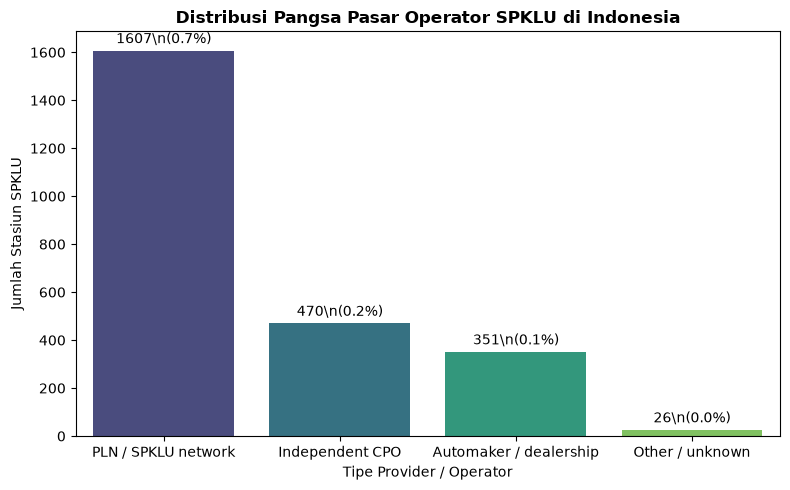

In [15]:
# Menentukan ukuran kanvas gambar (lebar 8 inci, tinggi 5 inci) 
plt.figure(figsize=(8, 5))

# Membuat diagram batang (bar chart) menggunakan seaborn
ax = sns.barplot(x=kq1_df.index,                # Sumbu X: Nama tipe provider (PLN, CPO, Dealer)
                y=kq1_df["Jumlah Stasiun"],     # Sumbu Y: Jumlah stasiun
                palette="viridis"               # Skema warna grafik
                )

# Menambahkan judul grafik 
plt.title("Distribusi Pangsa Pasar Operator SPKLU di Indonesia", fontsize=12, fontweight="bold")

# Menambahkan label pada sumbu X 
plt.xlabel("Tipe Provider / Operator")

# Menambahkan label pada sumbu Y 
plt.ylabel("Jumlah Stasiun SPKLU")

# Melakukan perulangan (loop) untuk menambahkan label angka dan persentase di atas setiap batang
for p in ax.patches:
    height = p.get_height()                                 # Mengambil nilai tinggi/jumlah pada batang
    percentage = (height / len(spklu_curated))              # Menghitung ulang persentase presisi
    ax.annotate(f"{int(height)}\\n({percentage:.1f}%)",
                (p.get_x() + p.get_width() / 2., height),
                ha="center", va="bottom",
                fontsize=10, xytext=(0, 3),
                textcoords="offset points"
                )
   
# Mengatur tata letak elemen grafik agar tidak terpotong 
plt.tight_layout()

# Menampilkan grafik ke layar 
plt.show()

### E.1.3 Insight
**Insight:**
1. PT PLN (Persero) mendominasi pasar pengisian daya kendaraan listrik dengan menguasai 65,48% stasiun (1.607 stasiun), sementara sektor swasta (Independent CPO) dan produsen otomotif berfungsi sebagai penyedia pendukung
2. PLN selaku BUMN memegang kendali pasar mayoritas jaringan SPKLU di Indonesia. Hal tersebut menunjukkan posisi BUMN sebagai penggerak utama dalam penyediaan infrastruktur dasar kendaraan listrik.

## E.2 Key Question 2: Sebaran Power Tier per Kategori Lokasi
Pertanyaan: Bagaimana sebaran tingkat daya pengisian pada masing-masing kategori lokasi?

### E.2.1 Kalkulasi Data
Menghitung jumlah power_tier berdasrakan kategori lokasi

In [16]:
# Membuat tabel kontingensi/crosstab antara kelompok lokasi dan tingkat daya pengisi 
kq2_crosstab = pd.crosstab(spklu_curated["location_group"],        # Baris: Kategori kelompok lokasi (Mall, Rest Area, dll) 
                           spklu_curated["station_power_tier"]    # Kolom: Tingkat daya (AC Slow, DC Fast, dll) 
                           )

# Menampilkan tabel kontingensi jumlah absolut 
print("TABULASI SILANG KATEGORI LOKASI VS POWER TIER") 
display(kq2_crosstab)

TABULASI SILANG KATEGORI LOKASI VS POWER TIER


station_power_tier,AC fast (11-22 kW),AC slow (<=7 kW),DC fast (25-49 kW),DC rapid (50-99 kW),DC ultra-rapid (>=100 kW)
location_group,,,,,
Hospitality,133,28,3,7,6
Office & Residential,169,8,22,17,15
Other / Unclassified,327,44,39,54,53
Public & Civic,107,15,13,19,10
Retail & Commercial,241,119,24,147,35
Transport corridor,17,2,6,42,46
Utility (PLN site),407,68,91,82,38


In [17]:
# Menghitung proporsi persentase per baris (normalize="index") untuk visualisasi relatif 
kq2_perc = pd.crosstab(spklu_curated["location_group"], 
                       spklu_curated["station_power_tier"], 
                       normalize="index") * 100                         # Mengubah nilai menjadi proporsi per lokasi (total 100%)

display(kq2_perc)

station_power_tier,AC fast (11-22 kW),AC slow (<=7 kW),DC fast (25-49 kW),DC rapid (50-99 kW),DC ultra-rapid (>=100 kW)
location_group,,,,,
Hospitality,75.141243,15.819209,1.694915,3.954802,3.389831
Office & Residential,73.160173,3.463203,9.523810,7.359307,6.493506
Other / Unclassified,63.249516,8.510638,7.543520,10.444874,10.251451
Public & Civic,65.243902,9.146341,7.926829,11.585366,6.097561
Retail & Commercial,42.579505,21.024735,4.240283,25.971731,6.183746
Transport corridor,15.044248,1.769912,5.309735,37.168142,40.707965
Utility (PLN site),59.329446,9.912536,13.265306,11.953353,5.539359


### E.1.2 Visualisasi Data
Menampilkan jumlah power_tier berdasrakan kategori lokasi dalam bentuk grafik

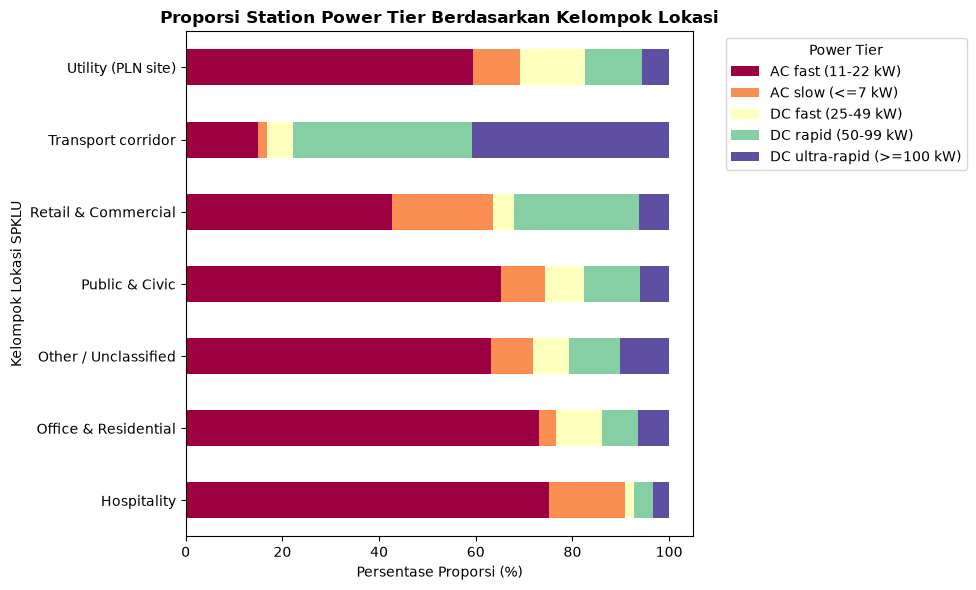

In [18]:
# Membuat diagram batang bertumpuk horizontal (horizontal stacked bar chart)
ax2 = kq2_perc.plot(kind="barh",                # Jenis chart: Bar Horizontal
                    stacked=True,               # Fitur bertumpuk aktif (stacked)
                    figsize=(10, 6),            # Ukuran grafik (10x6 inci)
                    colormap="Spectral"         # Gradasi warna variasi daya
                    )

# Menambahkan judul pada grafik
plt.title("Proporsi Station Power Tier Berdasarkan Kelompok Lokasi", fontsize=12, fontweight="bold")

# Menambahkan label sumbu X 
plt.xlabel("Persentase Proporsi (%)")

# Menambahkan label sumbu Y 
plt.ylabel("Kelompok Lokasi SPKLU")

# Menempatkan legenda (keterangan warna) di luar area grafik agar rapi 
plt.legend(title="Power Tier", bbox_to_anchor=(1.05, 1), loc="upper left")

# Mengatur tata letak agar grafik rapi 
plt.tight_layout()

# Menampilkan grafik 
plt.show()

### E.2.3 Insight
**Insight:**
1. Lokasi Transport corridor (seperti rest area tol) secara masif difokuskan pada pengisian cepat, dimana sekitar 77,9% stasiun menggunakan DC Rapid (42 stasiun) dan DC Ultra-rapid (46 stasiun). Langkah ini penting untuk meminimalisir waktu tunggu (downtime) pengisian daya saat perjalanan jarak jauh.
2. Lokasi milik PLN (Utility site) menjadi penopang utama dengan volume terbanyak di hampir seluruh tingkat daya, terutama AC Fast (407 stasiun) dan DC Fast (91 stasiun), yang memfasilitasi kebutuhan pengisian harian masyarakat secara umum.

## E.3 Key Question 3: Kesenjangan Rasio Per Kapita &amp; PDRB per Provinsi
Pertanyaan: Provinsi mana saja yang memiliki rasio cakupan SPKLU terendah per 100.000 penduduk (stations_per_100k) dan per triliun Rupiah PDRB (stations_per_trillion_gdp)?

### E.3.1 Kalkulasi Data
Identifikasi provinsi yang memiliki rasio cakupan SPKLU terendah per 100.000 penduduk

In [19]:
# Melakukan pengelompokan (grouping) data berdasarkan nama provinsi
kq3_prov = spklu_curated.groupby("province_name")[[
                                "stations_per_100k",                # Mengambil kolom rasio per 100k penduduk
                                "stations_per_trillion_gdp"         # Mengambil kolom rasio per triliun PDRB
                                ]].mean().reset_index()             # Menhitung nilai rata-rata dan mengembalikan index

# Menampilkan 5 provinsi dengan rasio per kapita terendah
print("5 PROVINSI DENGAN RASIO TERENDAH PER 100.000 PENDUDUK") 
display(kq3_prov.sort_values(by="stations_per_100k", ascending=True).head(5))

5 PROVINSI DENGAN RASIO TERENDAH PER 100.000 PENDUDUK


,province_name,stations_per_100k,stations_per_trillion_gdp
23,Papua,0.349,0.048
18,Lampung,0.389,0.067
29,Sulawesi Tenggara,0.419,0.054
17,Kepulauan Riau,0.484,0.026
10,Jawa Timur,0.487,0.058


### E.3.2 Visualisasi Data
Menampilkan provinsi yang memiliki rasio cakupan SPKLU terendah per 100.000 penduduk dalam bentuk grafik

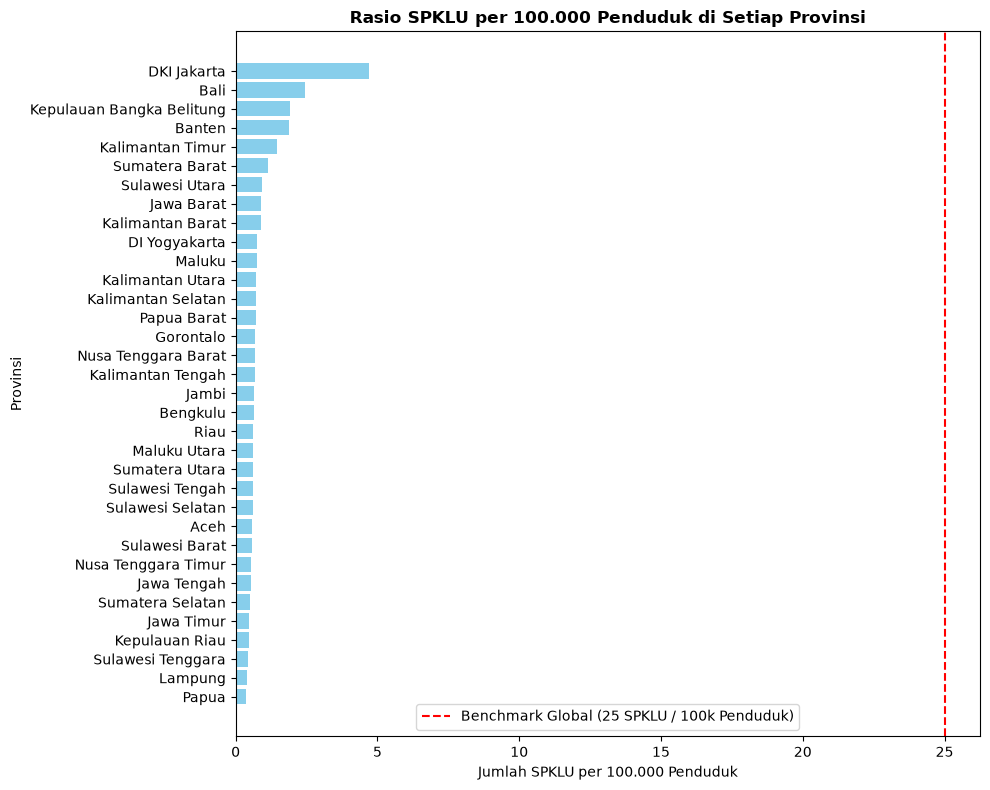

In [20]:
# Menentukan ukuran kanvas grafik 
plt.figure(figsize=(10, 8))

# Mengurutkan data provinsi dari rasio terendah ke tertinggi untuk plot 
sorted_prov = kq3_prov.sort_values(by="stations_per_100k", ascending=True)

# Membuat horizontal bar chart
plt.barh(
        sorted_prov["province_name"],           # Sumbu Y: Nama provinsi
        sorted_prov["stations_per_100k"],       # Sumbu X: Nilai rasio per 100k penduduk
        color="skyblue")                        # Warna batang grafik

# Menambahkan garis acuan (reference benchmark line) bernilai 25 per 100k penduduk 
plt.axvline(x=25,
            color="red",                                                # Posisi garis pada angka 25
            linestyle="--",
            label="Benchmark Global (25 SPKLU / 100k Penduduk)")        # Teks keterangan pada legenda

# Menambahkan judul grafik 
plt.title("Rasio SPKLU per 100.000 Penduduk di Setiap Provinsi", fontsize=12, fontweight="bold")

# Menambahkan label sumbu X 
plt.xlabel("Jumlah SPKLU per 100.000 Penduduk")

# Menambahkan label sumbu Y 
plt.ylabel("Provinsi")

# Menampilkan legenda keterangan garis benchmark 
plt.legend()

# Mengatur tata letak grafik 
plt.tight_layout()

# Menampilkan grafik 
plt.show()

### E.3.3 Insight
**Insight:**
1. Ketersediaan infrastruktur SPKLU di seluruh provinsi Indonesia masih mengalami kesenjangan signifikan jika dibandingkan dengan tolok ukur global.
2. Seluruh provinsi di Indonesia berada jauh di bawah garis benchmark global sebesar 25 SPKLU per 100.000 penduduk. DKI Jakarta sebagai provinsi dengan rasio tertinggi (4,71 SPKLU per 100.000 penduduk) baru mencapai sekitar 18,8% dari target ideal global tersebut.
3. Penyebaran infrastruktur SPKLU sangat terpusat di pusat pemerintahan dan destinasi pariwisata utama, dengan DKI Jakarta dan Bali mendominasi peringkat teratas. Sebagian besar provinsi lainnya di kawasan Sumatra, Sulawesi, Kalimantan, hingga Papua memiliki rasio di bawah 1 SPKLU per 100.000 penduduk.
4. 5 Provinsi dengan Rasio Cakupan Terendah: 
    - Papua: 0,35 SPKLU / 100rb penduduk (0,05 / triliun Rp PDRB)
    - Lampung: 0,39 SPKLU / 100rb penduduk (0,07 / triliun Rp PDRB)
    - Sulawesi Tenggara: 0,42 SPKLU / 100rb penduduk (0,05 / triliun Rp PDRB)
    - Kepulauan Riau: 0,48 SPKLU / 100rb penduduk (0,03 / triliun Rp PDRB)
    - Jawa Timur: 0,49 SPKLU / 100rb penduduk (0,06 / triliun Rp PDRB) 

## E.4 Key Question 4: Identifikasi Charging Deserts (> 20 km)
Pertanyaan: Berapa proporsi stasiun SPKLU yang tergolong charging deserts (terisolasi secara spasial dengan nearest_road_km > 20 km dari stasiun lain)?

### E.4.1 Kalkulasi Data
Menghitung jumlah proporsi stasiun SPKLU yang termasuk charging deserts

In [21]:
# Membuat kolom Boolean baru "deserted" (True jika jarak ke stasiun terdekat > 20 km) 
spklu_curated["deserted"] = spklu_curated["nearest_road_km"] > 20

# Menghitung total frekuensi stasiun yang terisolasi vs tidak terisolasi 
desert_count = spklu_curated["deserted"].value_counts()

# Menghitung proporsi persentase stasiun terisolasi 
desert_pct = spklu_curated["deserted"].value_counts(normalize=True) * 100

# Menampilkan ringkasan teks hasil deteksi 
print("PROPORSI CHARGING DESERTS (>20 KM)")
print(f"Stasiun Terisolasi (>20 km) : {desert_count.get(True, 0)} titik ({desert_pct.get(True, 0):.2f}%)")
print(f"Stasiun Terlayani (<=20 km) : {desert_count.get(False, 0)} titik ({desert_pct.get(False, 0):.2f}%)")

PROPORSI CHARGING DESERTS (>20 KM)
Stasiun Terisolasi (>20 km) : 337 titik (13.73%)
Stasiun Terlayani (<=20 km) : 2117 titik (86.27%)


### E.4.2 Visualisasi Data
Menampilkan jumlah proporsi stasiun SPKLU yang termasuk charging deserts dalam bentuk grafik

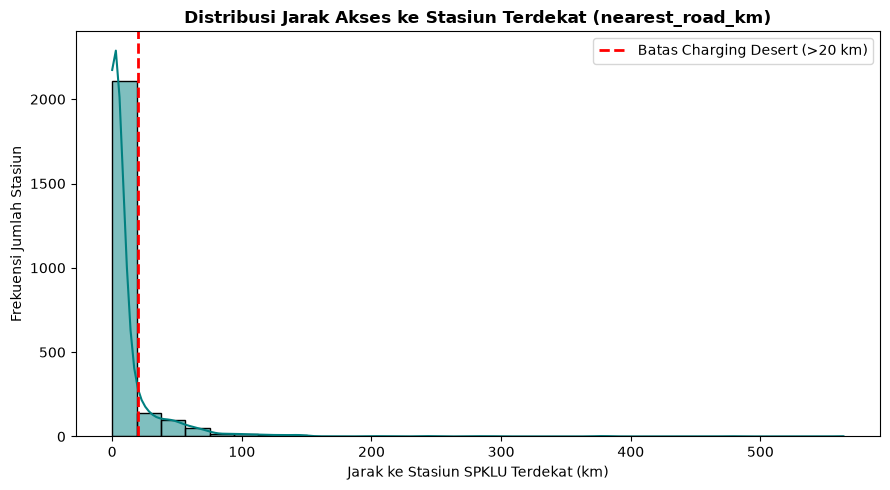

In [22]:
# Menentukan ukuran kanvas grafik 
plt.figure(figsize=(9, 5))

# Membuat histogram distribusi jarak dengan garis estimasi kepadatan (KDE)
sns.histplot(spklu_curated["nearest_road_km"],          # Data yang diplot: Jarak dalam kilometer
             bins=30,                                   # Jumlah kelompok batang (bins)
             kde=True,                                  # Menampilkan garis kurva KDE
             color="teal")                              # Warna batang histogram

# Menambahkan garis pemisah batas charging desert pada jarak 20 km 
plt.axvline(x=20,                                       # Posisi garis pada jarak 20 km
            color="red",
            linestyle="--",
            linewidth=2,
            label="Batas Charging Desert (>20 km)")

# Menambahkan judul grafik 
plt.title("Distribusi Jarak Akses ke Stasiun Terdekat (nearest_road_km)", fontsize=12, fontweight="bold")

# Menambahkan label sumbu X 
plt.xlabel("Jarak ke Stasiun SPKLU Terdekat (km)")

# Menambahkan label sumbu Y 
plt.ylabel("Frekuensi Jumlah Stasiun")

# Menampilkan legenda 
plt.legend()

# Mengatur tata letak 
plt.tight_layout()

# Menampilkan grafik
plt.show()

### E.4.3 Insight
**Insight:**
1. Sebanyak 13,73% (337 titik) stasiun SPKLU teridentifikasi sebagai _charging deserts_ karena terisolasi secara spasial dengan jarak lebih dari 20 km dari stasiun terdekat. Sementara itu, 86,27% (2.117 titik) sisanya berada dalam jaringan yang terlayani.
2. Grafik menunjukkan puncak frekuensi (peak) yang sangat tinggi pada kisaran jarak 0–20 km. Hal ini menandakan bahwa mayoritas SPKLU saat ini dibangun secara terkelompok (clustered) di pusat-pusat aktivitas atau area perkotaan padat.
3. Kurva distribusi menunjukkan ekor yang memanjang hingga jarak 100–500 km. Hal ini mengindikasikan masih tingginya kesenjangan konektivitas antar daerah

## E.5 Key Question 5: Statistik Deskriptif (Daya dan Jarak)
Pertanyaan: Berapa nilai rata-rata (mean), nilai tengah (median), standar deviasi, jangkauan antar-kuartil (IQR), serta batas pencilan (outliers) dari kapasitas daya dan jarak antar-stasiun di seluruh 2.454 lokasi?

### E.5.1 Kalkulasi Data
Menghitung nilai-nilai statistik deskriptif

#### E.5.1.1 Daya (station_power_kW)

In [23]:
# Mengambil data kolom daya terpasang 
daya = spklu_curated["station_power_kW"].dropna()

# Menghitung nilai statistik dasar 
mean_daya = daya.mean() 
median_daya = daya.median() 
std_daya = daya.std() 
q1_daya = daya.quantile(0.25) 
q3_daya = daya.quantile(0.75) 
iqr_daya = q3_daya - q1_daya

# Menghitung batas pencilan (outlier) untuk daya 
batas_bawah_daya = q1_daya - (1.5 * iqr_daya) 
batas_atas_daya = q3_daya + (1.5 * iqr_daya)

# Menghitung jumlah outlier daya (data di luar batas bawah dan atas) 
outlier_daya = daya[(daya < batas_bawah_daya) | (daya > batas_atas_daya)] 
jumlah_outlier_daya = len(outlier_daya)

#### E.5.1.2 Jarak (nearest_road_km)

In [24]:
# Mengambil data kolom jarak terdekat 
jarak = spklu_curated["nearest_road_km"].dropna()

# Menghitung nilai statistik dasar satu per satu 
mean_jarak = jarak.mean() 
median_jarak = jarak.median() 
std_jarak = jarak.std() 
q1_jarak = jarak.quantile(0.25) 
q3_jarak = jarak.quantile(0.75) 
iqr_jarak = q3_jarak - q1_jarak

# Menghitung batas pencilan (outlier) untuk jarak 
batas_bawah_jarak = q1_jarak - (1.5 * iqr_jarak) 
batas_atas_jarak = q3_jarak + (1.5 * iqr_jarak)

# Menghitung jumlah outlier jarak (data di luar batas bawah dan atas) 
outlier_jarak = jarak[(jarak < batas_bawah_jarak) | (jarak > batas_atas_jarak)] 
jumlah_outlier_jarak = len(outlier_jarak)

#### E.5.1.3 Daya dan Jarak

In [25]:
# Membuat tabel ringkasan secara langsung menggunakan DataFrame 
tabel_statistik = pd.DataFrame({"Ukuran Statistik": [
                                    "Rata-rata (Mean)", 
                                    "Nilai Tengah (Median)",
                                    "Standar Deviasi", 
                                    "Kuartil 1 (Q1)", 
                                    "Kuartil 3 (Q3)", 
                                    "Jangkauan Antar-Kuartil (IQR)", 
                                    "Batas Bawah Outlier", 
                                    "Batas Atas Outlier", 
                                    "Jumlah Outliers"],
                                "Daya Terpasang (kW)": [ 
                                    round(mean_daya, 2),
                                    round(median_daya, 2), 
                                    round(std_daya, 2), 
                                    round(q1_daya, 2), 
                                    round(q3_daya, 2), 
                                    round(iqr_daya, 2), 
                                    round(batas_bawah_daya, 2), 
                                    round(batas_atas_daya, 2), 
                                    jumlah_outlier_daya],
                                "Jarak Terdekat (km)": [ 
                                    round(mean_jarak, 2), 
                                    round(median_jarak, 2), 
                                    round(std_jarak, 2), 
                                    round(q1_jarak, 2), 
                                    round(q3_jarak, 2), 
                                    round(iqr_jarak, 2), 
                                    round(batas_bawah_jarak, 2), 
                                    round(batas_atas_jarak, 2), 
                                    jumlah_outlier_jarak]
                                })

# Menampilkan tabel statistik deskriptif 
print("TABEL RINGKASAN STATISTIK DESKRIPTIF") 
display(tabel_statistik)

TABEL RINGKASAN STATISTIK DESKRIPTIF


,Ukuran Statistik,Daya Terpasang (kW),Jarak Terdekat (km)
0,Rata-rata (Mean),36.62,10.86
1,Nilai Tengah (Median),22.00,2.09
2,Standar Deviasi,40.45,29.26
3,Kuartil 1 (Q1),22.00,0.98
4,Kuartil 3 (Q3),30.00,6.91
5,Jangkauan Antar-Kuartil (IQR),8.00,5.93
6,Batas Bawah Outlier,10.00,-7.91
7,Batas Atas Outlier,42.00,15.80
8,Jumlah Outliers,866.00,393.00


### E.5.2 Insight
**Insight:**
1. Ringkasan statistik deskriptif memperlihatkan adanya kemiringan distribusi (skewness) yang signifikan serta sebaran nilai ekstrem (outliers) pada kapasitas daya terpasang maupun jarak antarstasiun SPKLU.

## E.6 Key Question 6: Statistik Inferensial (Uji-T Jawa vs. Luar Jawa)
Pertanyaan: Apakah terdapat perbedaan yang signifikan secara statistik antara rata-rata kapasitas daya terpasang atau jarak antar-stasiun di wilayah Jawa vs. Luar Jawa?

### E.6.1 Kalkulasi Data
Menghitung statistik dasar kapasitas daya terpasang untuk grup pulau Jawa dan Luar Jawa

In [26]:
# Daftar nama provinsi yang termasuk dalam Pulau Jawa 
java_provinces = ["DKI Jakarta", "Jawa Barat", "Jawa Tengah", "DI Yogyakarta", "Jawa Timur", "Banten"]

# Membuat kolom Boolean "java": True jika provinsi berada di Pulau Jawa, False jika Luar Jawa 
spklu_curated["java"] = spklu_curated["province_name"].isin(java_provinces)

# Memisahkan sampel data daya (station\_power\_kW) untuk grup Pulau Jawa 
group_java = spklu_curated[spklu_curated["java"] == True]["station_power_kW"].dropna()

# Memisahkan sampel data daya (station\_power\_kW) untuk grup Luar Jawa 
group_non_java = spklu_curated[spklu_curated["java"] == False]["station_power_kW"].dropna()

# Menampilkan statistik dasar dari kedua grup sampel 
print("DESKRIPSI SAMPEL UJI-T") 
print(f"Grup Pulau Jawa : Rata-rata = {group_java.mean():.2f} kW | Total Stasiun (n) = {len(group_java)}") 
print(f"Grup Luar Jawa : Rata-rata = {group_non_java.mean():.2f} kW | Total Stasiun (n) = {len(group_non_java)}")

DESKRIPSI SAMPEL UJI-T
Grup Pulau Jawa : Rata-rata = 38.65 kW | Total Stasiun (n) = 1583
Grup Luar Jawa : Rata-rata = 32.93 kW | Total Stasiun (n) = 871


### E.6.2 Menjalankan Pengujian

In [27]:
# Menjalankan Uji-T 2 Sampel Independen (equal_var=False mengasumsikan varians kedua grup tidak harus sama) 
t_stat, p_value = stats.ttest_ind(group_java, group_non_java, equal_var=False)

# Menampilkan nilai statistik T dan P-Value
print("HASIL UJI HIPOTESIS INFERENSIAL") 
print(f"Nilai T-Statistic : {t_stat:.4f}") 
print(f"Nilai P-Value : {p_value:.4e}")

HASIL UJI HIPOTESIS INFERENSIAL
Nilai T-Statistic : 3.7066
Nilai P-Value : 2.1502e-04


In [28]:
# Menentukan tingkat signifikansi alpha = 0.05 (5%) 
alpha = 0.05

if p_value < alpha: 
    print("KESIMPULAN: Tolak H0!") 
    print("Terdapat perbedaan yang signifikan secara statistik pada rata-rata kapasitas daya terpasang (kW) antara Pulau Jawa dan Luar Jawa.") 
else: 
    print("KESIMPULAN: Gagal Tolak H0!") 
    print("Tidak terdapat perbedaan yang signifikan secara statistik pada rata-rata kapasitas daya terpasang (kW) antara Pulau Jawa dan Luar Jawa.")

KESIMPULAN: Tolak H0!
Terdapat perbedaan yang signifikan secara statistik pada rata-rata kapasitas daya terpasang (kW) antara Pulau Jawa dan Luar Jawa.


### E.6.3 Insight
**Insight:**
1. Hasil uji hipotesis inferensial (Uji-T 2 Sampel Independen) menunjukkan perbedaan yang signifikan secara statistik pada rata-rata kapasitas daya terpasang (kW) SPKLU antara Pulau Jawa dan Luar Jawa
2. Hasil Signifikan (Tolak $H_0$): Dengan nilai $t\text{-statistic} = 3{,}7066$ dan $p\text{-value} = 2{,}15 \times 10^{-4}$ (jauh di bawah batas signifikansi $\alpha = 0{,}05$), hipotesis nol ($H_0$) ditolak. Hal ini mengonfirmasi secara statistik bahwa ketimpangan daya SPKLU antarwilayah bukan terjadi karena kebetulan.
3. Rata-rata daya terpasang SPKLU di Pulau Jawa mencapai 38,65 kW, sedangkan di Luar Jawa berada di angka 32,93 kW (selisih ~5,72 kW). Hal ini mengindikasikan bahwa Pulau Jawa lebih banyak dilengkapi oleh stasiun pengisian daya cepat (DC Fast / Rapid).
4. Secara kuantitas webanyak 64,5% stasiun pengisian daya (1.583 titik) terpusat di Pulau Jawa, dibandingkan 35,5% (871 titik) di Luar Jawa. Selain itu, stasiun di Luar Jawa secara umum memiliki spesifikasi daya pengisian yang lebih rendah.

# E. Pengambilan Kesimpulan
Tahapan ini merupakan tahap terakhir, yang berisi kesimpulan berupa solusi/rekomendasi/jawaban atas permasalahan yang diangkat serta menarik benang merah dari seluruh analisis dan perhitungan secara singkat, jelas, dan padat.



**Temuan:**
1. Infrastruktur SPKLU di Indonesia saat ini berada pada tahap awal yang didominasi oleh BUMN (PT PLN), dengan tingkat penyebaran yang masih terpusat di pusat perkotaan Pulau Jawa serta menghadapi ketimpangan cakupan secara nasional. PT PLN (Persero) menjadi tulang punggung utama dengan menguasai 65,48% stasiun (1.607 stasiun). Peran CPO swasta independen (19,15%) dan dealer otomotif (14,30%) berfungsi sebagai penyedia pendukung yang mengimbangi area komersial dan ruang privat.
2. Uji hipotesis inferensial meununjukkan secara signifikan ($p = 2,15 \times 10^{-4} < 0,05$) adanya jurang pemisah antara Pulau Jawa dan Luar Jawa. Pulau Jawa tidak hanya unggul secara kuantitas (menguasai 64,5% stasiun), tetapi juga secara kualitas daya terpasang (rata-rata 38,65 kW di Jawa vs 32,93 kW di Luar Jawa).
3. Terkait charging desert setidaknya terdapat 13,73% (337 titik) stasiun yang terisolasi dengan jarak lebih dari 20 km dari stasiun terdekat. Kondisi ini berpotensi memicu range anxiety serta kerentanan jaringan akibat ketiadaan cadangan alternatif.

**Evaluasi:**
1. Pemerintah dan PT PLN perlu memprioritaskan alokasi anggaran pembangunan SPKLU baru di wilayah Luar Jawa, tidak hanya menambah jumlah unit tetapi juga meningkatkan kapasitas ke tipe DC Fast/Rapid Charging.
2. Pembangunan titik SPKLU baru baiknya difokuskan pada koridor antar kota dan area terisolasi guna memberikan redundansi jaringan dan menjamin konektivitas antar wilayah.

In [29]:
# Export DataFrame gabungan ke file CSV untuk Tableau 
spklu_curated.to_csv("spklu_curated.csv", index=False)